# Partie 3 — Volatilité conditionnelle : le modèle GARCH

**Objectif :** la partie 1 a montré que la volatilité change dans le temps (clustering).
Les VaR de la partie 2 l'ignorent : elles utilisent une seule volatilité pour toute la période.
Le GARCH prévoit la volatilité **de demain** à partir de ce qui s'est passé **aujourd'hui**,
ce qui donne une VaR **conditionnelle**, adaptée au contexte du moment.

In [10]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_prices, compute_returns, portfolio_losses
from src.risk_measures import var_hist, es_hist, var_gaussien, es_gaussien
from src.garch import fit_garch, garch_var_es

tickers = ["TTE.PA", "BNP.PA", "MC.PA", "AIR.PA", "SAN.PA"]
prices = load_prices(tickers, "2005-01-01", "2025-12-31", "../data/prices.csv")
returns = compute_returns(prices)
losses = portfolio_losses(returns)
port_returns = -losses

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Le modèle GARCH(1,1)

$$\sigma^2_{t+1} = \omega + a\,\varepsilon_t^2 + b\,\sigma_t^2$$

La variance de demain dépend de 3 éléments :
- **ω** : un plancher minimum ;
- **a × choc d'aujourd'hui²** : la **réaction** (un gros choc aujourd'hui rend demain plus agité) ;
- **b × variance d'aujourd'hui** : la **mémoire** (une période agitée dure).

**Persistance a + b** : proche de 1, les chocs de volatilité mettent longtemps à disparaître.

On va estime deux versions :
- **GARCH normal** : les chocs suivent une loi normale ;
- **GARCH-t** : les chocs suivent une loi de Student, qui a des queues plus épaisses (paramètre ν).



In [11]:
res_n = fit_garch(port_returns, dist="normal")
res_t = fit_garch(port_returns, dist="t")

# ---- GARCH normal ----
a_n = res_n.params["alpha[1]"]
b_n = res_n.params["beta[1]"]
omega_n = res_n.params["omega"]
pers_n = a_n + b_n

# ---- GARCH-t ----
a_t = res_t.params["alpha[1]"]
b_t = res_t.params["beta[1]"]
omega_t = res_t.params["omega"]
pers_t = a_t + b_t
nu_t = res_t.params["nu"]

# ---- Tableau ----
tableau_params = pd.DataFrame({
    "GARCH normal": [a_n, b_n, pers_n, res_n.aic],
    "GARCH-t":      [a_t, b_t, pers_t, res_t.aic],
}, index=["a (réaction)", "b (mémoire)", "persistance a+b", "AIC"])

print("nu (GARCH-t) :", nu_t)
tableau_params.round(3)

nu (GARCH-t) : 6.166728754436278


,GARCH normal,GARCH-t
a (réaction),0.103,0.100
b (mémoire),0.876,0.884
persistance a+b,0.978,0.983
AIC,17435.171,17160.091


Le **GARCH-t est nettement préféré**.

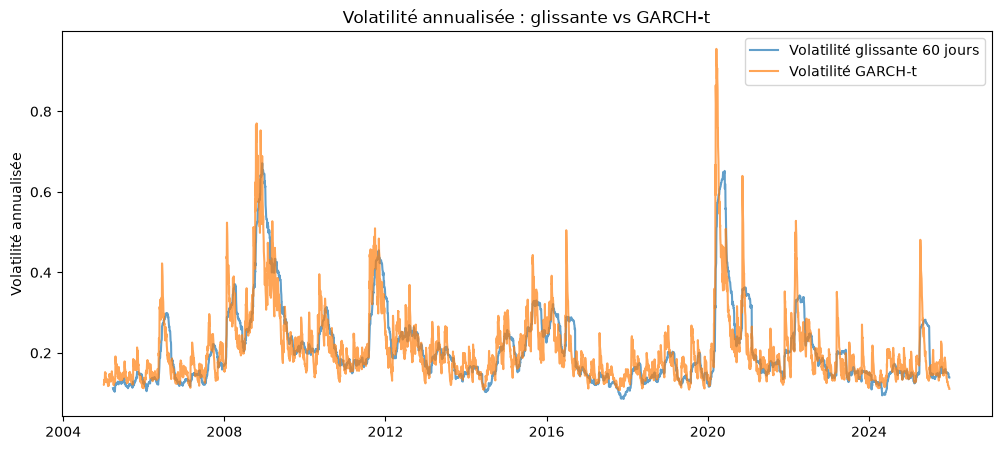

In [12]:
vol_garch = res_t.conditional_volatility / 100 * np.sqrt(252)
vol_glissante = port_returns.rolling(60).std() * np.sqrt(252)

plt.figure(figsize=(12, 5))
plt.plot(vol_glissante, label="Volatilité glissante 60 jours", alpha=0.7)
plt.plot(vol_garch, label="Volatilité GARCH-t", alpha=0.7)
plt.title("Volatilité annualisée : glissante vs GARCH-t")
plt.ylabel("Volatilité annualisée")
plt.legend()
plt.savefig("../figures/vol_garch_vs_glissante.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation

- **Le GARCH réagit immédiatement aux chocs** : en mars 2020, il monte à ≈ 95 % en quelques jours,
  contre un pic de ≈ 65 % pour la volatilité glissante, qui moyenne 60 jours.
- **Il redescend plus vite**, sans l'effet fantôme de la fenêtre glissante
  (qui reste haute tant que le krach est dans les 60 derniers jours).
- **Il détecte des chocs courts** que la moyenne glissante lisse : Brexit (2016), 2022, avril 2025.

Une VaR fondée sur une volatilité « lente » risque donc d'être en retard au début des crises.

In [13]:
tableau_var = pd.DataFrame({
    "VaR 95%": [var_hist(losses, 0.95), var_gaussien(losses, 0.95),
                garch_var_es(res_n, 0.95)[0], garch_var_es(res_t, 0.95)[0]],
    "VaR 99%": [var_hist(losses, 0.99), var_gaussien(losses, 0.99),
                garch_var_es(res_n, 0.99)[0], garch_var_es(res_t, 0.99)[0]],
    "ES 99%":  [es_hist(losses, 0.99), es_gaussien(losses, 0.99),
                garch_var_es(res_n, 0.99)[1], garch_var_es(res_t, 0.99)[1]],
}, index=["Historique (non cond.)", "Gaussienne (non cond.)",
          "GARCH normal (demain)", "GARCH-t (demain)"])

(tableau_var * 100).round(2)

,VaR 95%,VaR 99%,ES 99%
Historique (non cond.),2.18,4.20,5.76
Gaussienne (non cond.),2.33,3.30,3.79
GARCH normal (demain),1.18,1.70,1.96
GARCH-t (demain),1.10,1.83,2.36


## 3. VaR et ES : comparaison des 4 méthodes

On compare la VaR et l'ES obtenues par 4 méthodes. Toutes utilisent les 20 ans de données, mais pas de la même façon :

| Méthode | Comment elle calcule | VaR qui change selon le moment ? |
|---|---|---|
| **Historique** | trie les pertes des 20 ans et prend celle à 95 % ou 99 % ; l'ES est la moyenne des pertes au-delà | Non |
| **Gaussienne** | calcule la moyenne μ et l'écart-type σ des 20 ans, puis VaR = μ + σ × z (z = 2,33 à 99 %) | Non |
| **GARCH normal** | apprend ses règles (ω, a, b) sur 20 ans, prévoit σ de demain à partir de la variance et du choc d'aujourd'hui, puis VaR = μ + σ_demain × z | Oui |
| **GARCH-t** | même chose, mais avec z tiré d'une loi de Student (queues épaisses, z ≈ 2,56 à 99 %) | Oui |

**En résumé :**
- l'historique et la gaussienne donnent le **risque moyen sur 20 ans**, le même chaque jour ;
- le GARCH donne le **risque de demain**, compte tenu de ce qui se passe en ce moment.

Les VaR GARCH sont calculées pour le jour qui suit la fin des données (fin décembre 2025).
Les résultats sont en % de la valeur du portefeuille.

### Interprétation (en % de la valeur du portefeuille)

**Les VaR GARCH sont environ 2 fois plus faibles que la VaR historique** (1,83 % contre 4,20 % à 99 %).
Ce n'est pas une erreur : elles ne répondent pas à la même question.
- La VaR **historique** moyenne **20 ans**, crises comprises.
- La VaR **GARCH** prévoit le risque **de demain**. Fin 2025, le marché est calme
  (σ prévue de 0,75 % par jour, soit environ 12 % par an), donc le risque prévu est faible.
  En mars 2020, elle aurait été bien supérieure à la VaR historique.

**Normal vs Student** : on retrouve l'effet de la partie 2.
À 95 %, la VaR Student est légèrement plus faible ; à 99 %, elle est plus élevée,
et l'**ES Student dépasse de 20 % l'ES normale** (2,36 % contre 1,96 %).

Sur un portefeuille de 1 000 000 €, la VaR GARCH-t 99 % à 1 jour est d'environ **18 300 €**.

## Conclusion

- La volatilité du portefeuille est **fortement persistante** (a + b ≈ 0,98) : les périodes agitées durent plusieurs semaines.
- Le **GARCH-t** est préféré au GARCH normal (AIC) : il faut **à la fois** une volatilité variable
  **et** des queues épaisses (ν ≈ 6) pour décrire les pertes.
- La VaR GARCH **s'adapte au contexte** : faible en période calme, élevée en crise.
  La VaR historique, elle, est la même tous les jours enfin elle verie de peu chaque jour car ya une valeur qui s"ajoutent.

